In [3]:
import pandas as pd
import numpy as np
import joblib
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

df = pd.read_csv("../data/cleaned/cleaned_credit_default.csv")

best_xgb = joblib.load("../models/best_xgboost.joblib")
encoder = joblib.load("../models/agegroup_encoder.joblib")

In [2]:
y = df["SeriousDlqin2yrs"]
X = df.drop(columns=["SeriousDlqin2yrs"])

categorical_cols = ["AgeGroup"]
numeric_cols = X.columns.difference(categorical_cols).tolist()

X_cat = encoder.transform(X[categorical_cols])
X_num = X[numeric_cols].to_numpy()

X_final = np.hstack([X_num, X_cat])

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X_final,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
y_prob = best_xgb.predict_proba(X_test)[:, 1]

threshold = 0.45

y_pred = (y_prob >= threshold).astype(int)

In [9]:
error_df = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": y_pred,
    "Probability": y_prob
})

error_df["ErrorType"] = np.select(
    [
        (error_df["Actual"] == 0) & (error_df["Predicted"] == 0),
        (error_df["Actual"] == 0) & (error_df["Predicted"] == 1),
        (error_df["Actual"] == 1) & (error_df["Predicted"] == 0),
        (error_df["Actual"] == 1) & (error_df["Predicted"] == 1)
    ],
    [
        "True Negative",
        "False Positive",
        "False Negative",
        "True Positive"
    ],
    default="Unknown"
)

error_df

,Actual,Predicted,Probability,ErrorType
0,1,1,0.487261,True Positive
1,0,0,0.038689,True Negative
2,0,0,0.048837,True Negative
3,1,0,0.307116,False Negative
4,0,0,0.041240,True Negative
...,...,...,...,...
29799,0,0,0.154113,True Negative
29800,0,0,0.167873,True Negative
29801,0,0,0.018951,True Negative
29802,1,0,0.174601,False Negative


In [10]:

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[26375  1455]
 [ 1026   948]]


In [11]:
TN, FP, FN, TP = cm.ravel()

print("True Negatives:", TN)
print("False Positives:", FP)
print("False Negatives:", FN)
print("True Positives:", TP)

True Negatives: 26375
False Positives: 1455
False Negatives: 1026
True Positives: 948


In [12]:
false_positive_rate = FP / (FP + TN)
false_negative_rate = FN / (FN + TP)

print("False Positive Rate:", false_positive_rate)
print("False Negative Rate:", false_negative_rate)

False Positive Rate: 0.05228171038447718
False Negative Rate: 0.5197568389057751


In [13]:
fp_percentage = FP / len(y_test)
fn_percentage = FN / len(y_test)

print("FP % of test set:", fp_percentage)
print("FN % of test set:", fn_percentage)

FP % of test set: 0.04881895047644611
FN % of test set: 0.034424909408133135


In [14]:
fp_probs = y_prob[(y_test.to_numpy() == 0) & (y_pred == 1)]
fn_probs = y_prob[(y_test.to_numpy() == 1) & (y_pred == 0)]

print("False Positive probability range:")
print(fp_probs.min(), fp_probs.max())

print("\nFalse Negative probability range:")
print(fn_probs.min(), fn_probs.max())

False Positive probability range:
0.45017377 0.9145075

False Negative probability range:
0.012281313 0.44996917


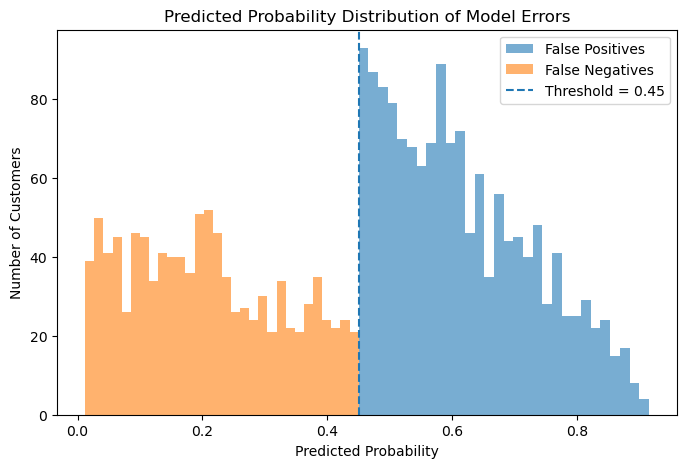

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(fp_probs, bins=30, alpha=0.6, label="False Positives")
plt.hist(fn_probs, bins=30, alpha=0.6, label="False Negatives")

plt.axvline(
    0.45,
    linestyle="--",
    label="Threshold = 0.45"
)

plt.xlabel("Predicted Probability")
plt.ylabel("Number of Customers")
plt.title("Predicted Probability Distribution of Model Errors")
plt.legend()
plt.show()

# Error Analysis

## Objective

The purpose of this notebook is to understand how the final XGBoost model makes prediction errors and to examine the difference between false positives and false negatives.

The final classification threshold selected during threshold optimization was **0.45**. Therefore, a predicted probability greater than or equal to 0.45 is classified as default.

The primary focus of this analysis is to understand the model's mistakes rather than only evaluating its overall performance.

---

## Final Confusion Matrix

The model was evaluated on the test set using the selected threshold of 0.45.

The resulting confusion matrix was:

```text
[[26375  1455]
 [ 1026   948]]
```

This corresponds to:

- **True Negatives (TN):** 26,375
- **False Positives (FP):** 1,455
- **False Negatives (FN):** 1,026
- **True Positives (TP):** 948

True negatives are customers correctly identified as non-defaulters, while true positives are customers correctly identified as defaulters.

False positives are customers predicted as defaulters who actually did not default. False negatives are customers who actually defaulted but were predicted as non-defaulters.

---

## False Positive and False Negative Analysis

The model produced 1,455 false positives and 1,026 false negatives.

The false positive rate was approximately **5.23%**, meaning that among customers who actually did not default, approximately 5.23% were incorrectly classified as defaulters.

The false negative rate was approximately **51.98%**, meaning that among customers who actually defaulted, approximately 51.98% were missed by the model.

The false-negative rate is important because the model's ability to identify actual defaulters is reflected directly in its recall.

The selected threshold of 0.45 was chosen to improve the balance between precision and recall compared with the default threshold of 0.50.

---

## Predicted Probability Distribution of Errors

The predicted probabilities of false positives and false negatives were examined relative to the selected threshold of 0.45.

False positives have predicted probabilities greater than or equal to 0.45 because the model classified them as defaulters.

False negatives have predicted probabilities below 0.45 because the model classified them as non-defaulters.

The probability distribution shows that the errors are not limited to observations very close to the decision threshold.

Some false positives have relatively high predicted probabilities, while a considerable number of false negatives have relatively low predicted probabilities.

This indicates that the model makes both borderline errors and relatively confident errors.

---

## Interpretation of False Positives

False positives represent customers who were predicted to default but actually did not default.

Their predicted probabilities are above the 0.45 threshold, with some observations receiving substantially higher probabilities.

This indicates that some non-defaulters have feature patterns that the model associates strongly with default risk.

Therefore, increasing the threshold would reduce some false positives, but it would also increase the number of false negatives.

---

## Interpretation of False Negatives

False negatives represent actual defaulters that the model failed to identify.

Their predicted probabilities are below the 0.45 threshold, and some have relatively low predicted probabilities.

This indicates that some actual defaulters have feature patterns that resemble those of non-defaulters, making them difficult for the model to identify correctly.

These cases are particularly important because they represent missed defaulters and directly affect recall.

---

## Key Findings

The error analysis produced several important observations:

- The final model correctly classified a large majority of the test observations.
- The model produced **1,455 false positives** and **1,026 false negatives** at the 0.45 threshold.
- The false-negative rate remains relatively high, indicating that identifying every actual defaulter is difficult.
- The probability distribution shows that model errors are not restricted to observations close to the classification threshold.
- Some false positives receive relatively high predicted probabilities.
- Some false negatives receive relatively low predicted probabilities.
- Therefore, simply changing the classification threshold cannot completely eliminate the model's errors.
- The results indicate that some defaulters and non-defaulters have overlapping feature patterns that are difficult for the model to distinguish.

---

## Conclusion

The error analysis shows that the XGBoost model provides good overall class separation but still produces both false positive and false negative predictions.

The selected threshold of **0.45** provides a better precision-recall balance than the default threshold of 0.50, but a substantial number of actual defaulters are still missed.

The probability analysis further shows that the model does not make errors only near the decision boundary. Some errors are relatively confident predictions, suggesting that the available features do not provide enough information to perfectly separate defaulters from non-defaulters.

Overall, the error analysis provides a more detailed understanding of the model's limitations beyond aggregate metrics such as accuracy, precision, recall, F1-score, and ROC-AUC.